[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/recsys/04-neighbourhood.ipynb)

# Neighbourhood Methods: User-Based, Item-Based, and the Rating Trap

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Build user-based and item-based neighbourhood recommenders and compare their cost and accuracy.</li>
<li>Predict rating values from neighbours' mean-centred ratings and measure the RMSE.</li>
<li>Show that a model with a good RMSE can rank like a random list, and explain why.</li>
<li>Use the ratings themselves to improve a ranking, while guarding against predictions with no evidence behind them.</li>
</ul>
</div>

**Prerequisites:** [Baselines](03-baselines.ipynb). **Dataset:** MovieLens small. **Time:** about 40 minutes.

## The situation

[Page 3](03-baselines.ipynb) used one fact: *who rated what*. It ignored the stars. Ratings carry more: a 5 says "loved it", a 1 says "avoid". Do they help? The obvious way to use them is to **predict the rating** a user would give each movie and recommend the highest predictions. This page tries that, and finds that the obvious way fails in an instructive manner.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_movielens, recsys as rs, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

## Maths ↔ code

- **User-based:** score of item $j$ for user $u$ is the similarity-weighted votes of $u$'s nearest neighbours who have $j$: $\sum_{v \in N_k(u)} \text{sim}(u,v)\,x_{vj}$. In code: `rs.user_similarity(X, k)` then `rs.user_knn_scores(X, S)`.
- **Item-based:** as on page 3, $\sum_{i \in I_u} \text{sim}(i,j)\,x_{ui}$ with `rs.item_similarity` and `rs.item_knn_scores`.
- **Mean-centring:** users use the scale differently, so replace $r_{ui}$ by $r_{ui} - \bar r_u$ (`rs.centre_users`).
- **Predicted rating** (item-based): $\hat r_{uj} = \bar r_u + \dfrac{\sum_{i} \text{sim}(i,j)\,(r_{ui}-\bar r_u)}{\sum_{i} |\text{sim}(i,j)| + \beta}$, summing over the items $i$ the user rated; $\beta$ is a shrinkage. In code: `rs.predict_ratings_knn(X, S, axis="item", shrink=beta)`.

## 0. Setup: the same task and validation split as before

In [2]:
ratings = load_movielens().ratings
task = rs.make_task(ratings)                             # test: each user's latest 20%
val = rs.make_task(task.train, index=task.index)         # validation: the latest 20% of the rest
n_users, n_items = task.X.shape

def ndcg(scores, t):
    return rs.evaluate(scores, t.B, t.relevant)["ndcg"].mean()

def per_user(scores):                                    # per-user NDCG on the TEST task, for paired comparisons
    return rs.evaluate(scores, task.B, task.relevant)["ndcg"]

index_of_user = pd.Series(range(n_users), index=task.index.users)
index_of_item = pd.Series(range(n_items), index=task.index.items)

def rmse(predicted, held_out):                           # error on the star values of a task's held-out ratings
    r, c = held_out.userId.map(index_of_user).to_numpy(), held_out.movieId.map(index_of_item).to_numpy()
    return float(np.sqrt(np.mean((predicted[r, c] - held_out.rating.to_numpy()) ** 2)))

## 1. User-based or item-based?

Both ask "who/what is similar?", from opposite sides. Tune the number of neighbours $k$ for each on the validation split (binary "has it" data, as on page 3, so only the *side* differs).

,user-based,item-based (shrinkage 50)
k,,
10,0.0849,0.0984
30,0.0980,0.1007
50,0.0988,0.1014
100,0.1008,0.1105
200,0.1004,0.1066
400,0.0992,0.1048


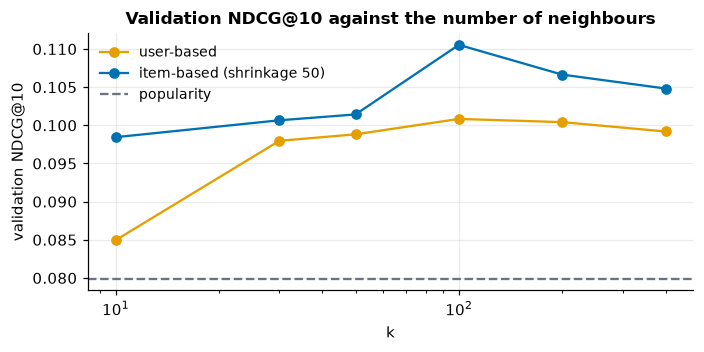

In [3]:
ks = (10, 30, 50, 100, 200, 400)
curve = pd.DataFrame({
    "user-based": [ndcg(rs.user_knn_scores(val.B, rs.user_similarity(val.B, k=k)), val) for k in ks],
    "item-based (shrinkage 50)": [ndcg(rs.item_knn_scores(val.B, rs.item_similarity(val.B, k=k, shrink=50)), val) for k in ks],
}, index=pd.Index(ks, name="k"))
display(curve)

fig, ax = plt.subplots(figsize=(6.5, 3.3))
curve.plot(ax=ax, marker="o", color=[style.ORANGE, style.BLUE])
ax.axhline(ndcg(rs.broadcast(rs.popularity(val.B), n_users), val), color=style.GREY, ls="--", label="popularity")
ax.set(xscale="log", ylabel="validation NDCG@10", title="Validation NDCG@10 against the number of neighbours"); ax.legend()
plt.tight_layout(); plt.show()

Both curves climb until about 100 neighbours and then level off or dip, and **both beat popularity** (the dashed line) once $k$ is 30 or more. The item-based side is ahead at every $k$ on validation (0.1105 against 0.1008 at $k = 100$); we use $k = 100$ for both sides below.

The two sides also differ enormously in **cost**, and which one is cheap depends on the shape of the data:

In [4]:
B = task.B
timing = {}
for name, build in {"user-user": lambda: rs.user_similarity(B, k=100), "item-item": lambda: rs.item_similarity(B, k=100, shrink=50)}.items():
    start = time.perf_counter(); build(); timing[name] = time.perf_counter() - start
cost = pd.DataFrame({
    "build time (s)": timing,
    "full similarity matrix (MB, float32)": {"user-user": n_users ** 2 * 4 / 1e6, "item-item": n_items ** 2 * 4 / 1e6},
})
cost

,build time (s),"full similarity matrix (MB, float32)"
user-user,0.0166,1.4884
item-item,1.1390,378.2247


Here the user side is cheap: 610 users against 9,724 movies makes the user-by-user matrix about **250 times** smaller (1.5 MB against 378 MB) and 70 times faster to build. At the scale of a real service, with millions of users and perhaps a hundred thousand items, the numbers reverse, which is why item-based methods are the usual industrial choice. *Which side is cheap is a property of the shape of your data.*

## 2. Predicting rating values

Now use the stars. Compare four ways to guess the rating of a held-out (user, movie) pair, scored by **RMSE** on the test ratings: the overall mean; the user's own mean; the **bias baseline** (overall mean plus a user offset plus a movie offset, `rs.bias_baseline`); and neighbourhood predictions from mean-centred ratings.

In [5]:
centred, user_mean = rs.centre_users(task.X)
overall_mean = task.X.data.mean()
mu, b_user, b_item = rs.bias_baseline(task.X)

S_item = rs.item_similarity(centred, k=100, shrink=50)     # similarity between movies, from centred ratings
S_user = rs.user_similarity(centred, k=50)

predictions = {
    "overall mean": np.full((n_users, n_items), overall_mean),
    "user mean": np.repeat(user_mean[:, None], n_items, axis=1),
    "bias baseline (user + movie offsets)": mu + b_user[:, None] + b_item[None, :],
    "item-based neighbours": rs.predict_ratings_knn(task.X, S_item, axis="item"),
    "user-based neighbours": rs.predict_ratings_knn(task.X, S_user, axis="user"),
}
table = pd.DataFrame({"test RMSE (stars)": {name: rmse(P, task.test) for name, P in predictions.items()}})
r = table["test RMSE (stars)"]
assert r.iloc[0] > r.iloc[1] > r.iloc[2] and r["bias baseline (user + movie offsets)"] < r["item-based neighbours"] < r["user-based neighbours"]
table

,test RMSE (stars)
overall mean,1.0693
user mean,0.9665
bias baseline (user + movie offsets),0.9023
item-based neighbours,0.9129
user-based neighbours,0.9548


Reading down: guessing the overall mean costs 1.069 stars of RMSE; each user's own mean 0.967; the **bias baseline** 0.902, so a per-user and a per-movie offset together are worth about 0.17 stars. The neighbourhood predictions beat the user mean (item-based 0.913, user-based 0.955) but **not the bias baseline**: centred only by user, they have no notion that some movies are better than others. Cheap offsets are hard to beat on RMSE, which is why every serious rating-prediction model starts from them (next page).

## 3. What goes wrong: the best predictor of ratings ranks like a random list

A model that predicts ratings well should surely recommend well: recommend the movies with the highest predicted rating. Rank every movie the user has not rated by `predictions["item-based neighbours"]` and score the top ten:

In [6]:
by_rating = predictions["item-based neighbours"]
print(f"NDCG@10 ranking by predicted rating: {ndcg(by_rating, task):.4f}")
print(f"NDCG@10 of a random list:            {ndcg(np.random.default_rng(0).random(task.B.shape), task):.4f}")
print(f"NDCG@10 of popularity:               {ndcg(rs.broadcast(rs.popularity(task.B), n_users), task):.4f}")
assert ndcg(by_rating, task) < 0.01

NDCG@10 ranking by predicted rating: 0.0027


NDCG@10 of a random list:            0.0023
NDCG@10 of popularity:               0.0743


The item-based predictor has an RMSE of 0.913 and yet, used to rank, it scores **0.0027, indistinguishable from a random list (0.0023) and far below popularity (0.0743)**. Good predictions of ratings produced recommendation lists that are no better than chance.

The reason is in the formula. For a movie that only one of the user's items is similar to, the sum has a single term, and dividing by $\sum|\text{sim}|$ turns a *weak* similarity into a *full-strength* prediction. Measure how much evidence stands behind each prediction, as the total similarity of the user's items that vote for a movie, the denominator above:

In [7]:
support = np.asarray((task.B @ abs(S_item).T).todense())            # users x movies: total similarity behind each prediction
top_by_rating = rs.top_k(by_rating, task.B, k=10)
evidence = np.take_along_axis(support, top_by_rating, axis=1)
unseen = task.B.toarray() == 0
print(f"unseen (user, movie) pairs with almost no evidence (total similarity < 0.5): {(support[unseen] < 0.5).mean():.1%}")
print(f"median total similarity behind the top-10 movies chosen by predicted rating: {np.median(evidence):.3f}")
top_binary = rs.top_k(rs.item_knn_scores(task.B, rs.item_similarity(task.B, k=100, shrink=50)), task.B, k=10)
print(f"... and behind the top 10 of the binary item-based model of page 3:            {np.median(np.take_along_axis(support, top_binary, axis=1)):.3f}")
assert np.median(evidence) < 0.05 and (support[unseen] < 0.5).mean() > 0.9

unseen (user, movie) pairs with almost no evidence (total similarity < 0.5): 97.3%
median total similarity behind the top-10 movies chosen by predicted rating: 0.012


... and behind the top 10 of the binary item-based model of page 3:            1.443


For **97.3% of the unseen (user, movie) pairs** there is almost no evidence (total similarity below 0.5), so a prediction for them is noise rescaled to look like a rating. Ranking by predicted rating sorts exactly those noisy extremes to the top: the median evidence behind a recommended movie is **0.012**, against 1.44 for the binary item-based model of page 3, a factor of more than a hundred. A predictor that is *accurate on average* is wrong in precisely the place a recommender looks.

**The fix** is the shrinkage $\beta$ in the denominator: it pulls predictions that rest on little evidence back toward the user's mean, so only movies that many similar items vote for can reach the top. Tune $\beta$ on the validation split. The table also shows the RMSE of each setting on the validation ratings:

In [8]:
v_centred, v_user_mean = rs.centre_users(val.X)
S_item_val = rs.item_similarity(v_centred, k=100, shrink=50)
sweep = pd.DataFrame({
    beta: {
        "validation RMSE": rmse(P := rs.predict_ratings_knn(val.X, S_item_val, axis="item", shrink=beta), val.test),
        "validation NDCG@10": ndcg(P, val),
    } for beta in (0, 1, 5, 20, 100, 500)
}).T.rename_axis("shrinkage beta")
best_beta = sweep["validation NDCG@10"].idxmax()
user_mean_rmse = rmse(np.repeat(v_user_mean[:, None], n_items, axis=1), val.test)
print(f"best shrinkage for ranking: beta = {best_beta:g}; for reference, predicting each user's mean has validation RMSE {user_mean_rmse:.4f}")
assert sweep["validation RMSE"].idxmin() == 0 and abs(sweep.loc[best_beta, "validation RMSE"] - user_mean_rmse) < 0.01
sweep

best shrinkage for ranking: beta = 100; for reference, predicting each user's mean has validation RMSE 0.9522


,validation RMSE,validation NDCG@10
shrinkage beta,,
0,0.9123,0.0014
1,0.9155,0.0917
5,0.9355,0.1053
20,0.9463,0.1073
100,0.9509,0.1083
500,0.9519,0.1082


With no shrinkage ($\beta = 0$) the RMSE is at its best (0.912) and the ranking at its worst (NDCG 0.0014, random). As $\beta$ grows the ranking recovers fast (0.092, 0.105, 0.107) and then plateaus at about 0.108 from $\beta = 100$, while the RMSE worsens to 0.951, **no better than predicting each user's mean (0.952)**. The two goals pull in opposite directions, and the plateau means the exact choice of $\beta$ matters little once it is large. We take $\beta = 100$.

## 4. The test set, once

Compare on the test split: popularity, the binary item-based and user-based models of page 3 (best $k$ from the validation curve), and the **centred-vote** versions that use the stars (neighbour votes weighted by $r - \bar r_u$, with the shrinkage tuned above).

In [9]:
best_k_item = curve["item-based (shrinkage 50)"].idxmax()
best_k_user = curve["user-based"].idxmax()

S_item_bin = rs.item_similarity(task.B, k=best_k_item, shrink=50)
S_user_bin = rs.user_similarity(task.B, k=best_k_user)
S_item_c = rs.item_similarity(centred, k=best_k_item, shrink=50)
S_user_c = rs.user_similarity(centred, k=best_k_user)

test = {
    "popularity": per_user(rs.broadcast(rs.popularity(task.B), n_users)),
    "user-based, binary": per_user(rs.user_knn_scores(task.B, S_user_bin)),
    "item-based, binary": per_user(rs.item_knn_scores(task.B, S_item_bin)),
    "user-based, centred ratings": per_user(rs.predict_ratings_knn(task.X, S_user_c, axis="user", shrink=best_beta)),
    "item-based, centred ratings": per_user(rs.predict_ratings_knn(task.X, S_item_c, axis="item", shrink=best_beta)),
}
rows = {}
for name, s in test.items():
    d_pop = rs.paired_difference(s, test["popularity"])
    d_bin = rs.paired_difference(s, test["item-based, binary"])
    rows[name] = {"test NDCG@10": s.mean(),
                  "vs popularity": "" if name == "popularity" else f"{d_pop['diff']:+.4f} [{d_pop['lo']:+.4f}, {d_pop['hi']:+.4f}]",
                  "vs item-based binary": "" if name == "item-based, binary" else f"{d_bin['diff']:+.4f} [{d_bin['lo']:+.4f}, {d_bin['hi']:+.4f}]"}
result = pd.DataFrame(rows).T
item_vs_user = rs.paired_difference(test["item-based, centred ratings"], test["user-based, centred ratings"])
print(f"item-based vs user-based, centred ratings: {item_vs_user['diff']:+.4f} [{item_vs_user['lo']:+.4f}, {item_vs_user['hi']:+.4f}]")
for name in ("item-based, centred ratings", "user-based, centred ratings"):          # guards the reading below
    assert rs.paired_difference(test[name], test["item-based, binary"])["lo"] > 0
assert item_vs_user["lo"] < 0 < item_vs_user["hi"]
result

item-based vs user-based, centred ratings: +0.0070 [-0.0036, +0.0176]


,test NDCG@10,vs popularity,vs item-based binary
popularity,0.0743,,"-0.0169 [-0.0286, -0.0053]"
"user-based, binary",0.0883,"+0.0140 [+0.0049, +0.0231]","-0.0029 [-0.0104, +0.0046]"
"item-based, binary",0.0913,"+0.0169 [+0.0053, +0.0286]",
"user-based, centred ratings",0.1045,"+0.0302 [+0.0218, +0.0387]","+0.0133 [+0.0010, +0.0255]"
"item-based, centred ratings",0.1115,"+0.0372 [+0.0248, +0.0496]","+0.0203 [+0.0086, +0.0320]"


Four readings of the table (intervals are paired differences, as on page 2).

1. **User-based and item-based tie** on binary data: -0.003 with an interval of [-0.010, +0.005] (the "vs item-based binary" column in the user-based row), and with centred ratings the item-based side is +0.007 ahead with an interval that contains zero. On this data the choice of side is a question of cost, not accuracy.
2. **Using the stars helps.** Item-based with centred ratings reaches 0.1115, **+0.020 over the binary item-based model** (interval [+0.009, +0.032]); user-based with centred ratings is also reliably above it (+0.013, interval [+0.001, +0.026]).
3. Against popularity the best model is **+0.037** (interval [+0.025, +0.050]): about 50% more NDCG than a non-personalised list.
4. This is the same information as the failed predicted-rating ranking of section 3, used with an evidence guard. The guard, not the stars, is what turned a random list into the best model so far.

<div class="admonition warning">
<p class="admonition-title">Watch out</p>
<p>A predicted rating is only trustworthy where there is evidence behind it, and the extremes of any ranked list are exactly where evidence is thinnest. Whenever a score is used to <em>rank</em>, ask how much data stands behind the top of the list.</p>
</div>

## Decision guide

| Situation | Use | Why |
|---|---|---|
| More items than users (this data) | Either; user-based is cheaper to build | The similarity matrix is users by users |
| Far more users than items (most products) | Item-based | A similarity table of items by items stays small and changes slowly |
| You need an explanation ("because you liked X") | Item-based | The nearest items *are* the explanation |
| You use the star values to rank | Centred ratings **with shrinkage** | Raw predicted ratings reward predictions with no evidence |
| You must show a rating prediction itself | A bias baseline or a factor model (next page), scored by RMSE | Neighbour predictions do not even beat a bias baseline here |

## Check yourself

<details class="question">
<summary>1. Why does subtracting each user's mean rating help a neighbourhood model?</summary>

A "3" from a generous user who gives 5s is a lukewarm vote; a "3" from a harsh user who gives 1s and 2s is praise. Centring replaces the raw star value by how far it is above or below *that user's* average, which makes votes from different users comparable.

</details>

<details class="question">
<summary>2. The best setting for ranking has an RMSE about the same as "predict each user's mean". Is that a contradiction?</summary>

No: the two goals pull in opposite directions. A low RMSE rewards being right on the *typical* pair, which is an ordinary movie with plenty of neighbours. A good ranking is decided at the *top of the list*, where only movies with strong evidence should appear. Shrinkage sacrifices the first for the second.

</details>

## Exercises

<details class="question">
<summary>Exercise 1 (easy): what would a "predict 3.5 stars for everything" recommender score on RMSE, and why is that a useful reference?</summary>

```python
print(rmse(np.full((n_users, n_items), 3.5), task.test))
```

It scores 1.0686, essentially the same as the overall-mean baseline (1.0693), because the training mean is almost exactly 3.5. Any model has to beat that constant before its RMSE means anything.

</details>

<details class="question">
<summary>Exercise 2 (medium): for the item-based model with the tuned shrinkage, split users at the median number of training ratings. Which group gains more over popularity?</summary>

```python
counts = pd.Series(np.asarray(task.B.sum(axis=1)).ravel())
a, b = test["item-based, centred ratings"], test["popularity"]
light, heavy = a.index[counts[a.index] <= counts.median()], a.index[counts[a.index] > counts.median()]
print(rs.paired_difference(a[light], b[light])); print(rs.paired_difference(a[heavy], b[heavy]))
```

Both groups gain: +0.032 for the lighter half (interval [+0.013, +0.051]) and +0.042 for the heavier half ([+0.026, +0.058]). The two intervals overlap heavily, so the data does not show that one group gains more. Check that before claiming a difference between groups.

</details>

<details class="question">
<summary>Exercise 3 (hard): in section 3 we ranked every unseen movie. Restrict the ranking to movies with at least 20 training ratings and re-score the unshrunk predictions. Does the evidence problem disappear?</summary>

```python
popular_enough = np.asarray(task.B.sum(axis=0)).ravel() >= 20
restricted = np.where(popular_enough[None, :], by_rating, -np.inf)
print(ndcg(restricted, task))
```

It helps a little, from 0.0027 to 0.0129 (1,052 movies remain), and stays about eight times below the shrinkage fix (0.1115). Filtering to popular movies removes the rarest items, but the *user's* evidence is still thin: even for a popular movie, the prediction can rest on one weakly similar item. The fix has to act on the evidence behind each prediction, which is what $\beta$ does.

</details>

## Recap

- **User-based and item-based** neighbourhood models work from opposite sides of the same matrix; here they tie on accuracy, and the cheaper side is the one with fewer rows or columns.
- **Mean-centring** makes users' ratings comparable. Predicted ratings from neighbours beat the user mean but not a plain bias baseline.
- **RMSE is the wrong yardstick for a ranking.** The ranking by predicted rating scores like a random list, because the top of the list is filled with predictions that rest on almost no evidence.
- **Shrinkage** fixes it: the setting that ranks best predicts ratings no better than the user mean.
- Used with that guard, the **stars improve the ranking** over the binary "has it" model.